# 04 Prescriptive analysis: referral pathway and referral slots (PB5)
Group 5 PROHI: Risk Factor Prediction of Chronic Kidney Disease

**User:** Clinical Care Coordinator. **Questions:** which patients should be flagged and referred, and at what risk threshold? Who gets the limited referral slots? Which modifiable factors (blood pressure, glucose, hypertension, diabetes) are most strongly associated with CKD, and how would changing them affect the predicted risk?

**Combined version** of two drafts: Pasanka's analysis (risk score for every patient, triage rules after blood tests, threshold rule with a 95% sensitivity target, OR-Tools selection for 5/10/15 slots with an early-stage rule, adjusted odds ratios with a worked what-if) and Victor's analysis (two-step pathway with a cheap screening step, intake rule from cheap tests, modifiable-factor odds ratios, blood pressure and glucose what-if, blood-test scheduling).

**Idea:** blood tests and specialist slots are limited, so the pathway has two steps. Step 1: everyone gets cheap checks (history, urine dipstick, blood pressure, age) and a cheap-test risk score. Step 2: flagged patients get blood tests and the full model; confirmed patients are referred, and OR-Tools decides who gets the limited referral slots.

The dataset has one visit per patient, so "risk" means risk of **current** CKD, not future progression. Blood pressure is only a category (0/1/2), so an exact mmHg threshold cannot be set.


In [ ]:
GITHUB_USER = "mhoyor"

%cd /content
!rm -rf ckd-risk-app
!git clone https://github.com/{GITHUB_USER}/ckd-risk-app.git
%cd /content/ckd-risk-app
!pip install -q ortools

/content
Cloning into 'ckd-risk-app'...
remote: Enumerating objects: 55, done.
remote: Counting objects: 100% (55/55), done.
remote: Compressing objects: 100% (54/54), done.
remote: Total 55 (delta 23), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (55/55), 1.09 MiB | 9.00 MiB/s, done.
Resolving deltas: 100% (23/23), done.
/content/ckd-risk-app


## Setup
Expected: `200 patients: 128 CKD and 72 non-CKD`.

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import confusion_matrix, roc_auc_score
from ortools.sat.python import cp_model
from data_prep import load_data, FEATURES
from viz import apply_style, COLORS, MUTED, TEXT, plot_readable_tree

apply_style()
os.makedirs("figures", exist_ok=True)

d = load_data()
df, raw = d["all"], d["raw"]
train, test = d["train"], d["test"]
y, y_train, y_test = df["class"], train["class"], test["class"]

# Cheap tests only (same list as PB4): history, urine dipstick, blood pressure and age
CHEAP = ["age", "bp", "bp limit", "sg", "al", "su", "htn", "dm", "cad", "appet", "pe"]
NAMES = {"age": "Age", "bp": "Diastolic BP flag", "bp limit": "BP category", "sg": "Urine specific gravity",
         "al": "Urine albumin", "su": "Urine sugar", "htn": "Hypertension", "dm": "Diabetes",
         "cad": "Coronary artery disease", "appet": "Poor appetite", "pe": "Pedal oedema",
         "hemo": "Haemoglobin", "pcv": "Packed cell volume", "rbcc": "Red blood cell count",
         "sod": "Sodium", "bu": "Blood urea", "sc": "Serum creatinine", "bgr": "Random blood glucose"}

def lr():
    return make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))

def sens_spec(y_true, flagged):
    tn, fp, fn, tp = confusion_matrix(y_true, flagged, labels=[0, 1]).ravel()
    return tp / (tp + fn), tn / (tn + fp), tp, fn, fp, tn

def cv_risk(cols, data, repeats=10):
    """Risk for each patient from models that did not see that patient (averaged over repeats)."""
    return np.mean([cross_val_predict(lr(), data[cols], data["class"],
                                      cv=StratifiedKFold(5, shuffle=True, random_state=r),
                                      method="predict_proba")[:, 1] for r in range(repeats)], axis=0)

def threshold_table(risk, y_true, grid):
    rows = []
    for t in grid:
        se, sp, *_ = sens_spec(y_true, (risk >= t).astype(int))
        rows.append({"Threshold": t, "Sensitivity": round(se, 3), "Specificity": round(sp, 3),
                     "% flagged": round(100 * (risk >= t).mean(), 1)})
    return pd.DataFrame(rows)

def threshold_chart(table, chosen, title, file, extra=None):
    fig, ax = plt.subplots(figsize=(8, 4.5))
    ax.plot(table["Threshold"], table["Sensitivity"], "-", marker="o", markersize=4, color="#6250d6", linewidth=2)
    ax.plot(table["Threshold"], table["Specificity"], "--", marker="o", markersize=4, color="#1baf7a", linewidth=2)
    ax.text(table["Threshold"].iloc[-1] + 0.01, table["Sensitivity"].iloc[-1], " Sensitivity\n (CKD caught)",
            va="center", color="#6250d6", fontsize=9)
    ax.text(table["Threshold"].iloc[-1] + 0.01, table["Specificity"].iloc[-1], " Specificity\n (healthy not flagged)",
            va="center", color="#1baf7a", fontsize=9)
    ax.axhline(0.95, color=MUTED, linewidth=0.8, linestyle=":")
    for t, label in [(chosen, f"chosen\n{chosen}")] + (extra or []):
        ax.axvline(t, color=TEXT if t == chosen else MUTED, linewidth=1 if t == chosen else 0.8,
                   linestyle="-" if t == chosen else ":")
        ax.text(t + 0.01, 0.40, label, fontsize=8, color=TEXT if t == chosen else MUTED)
    ax.set_xlim(0, 1.17); ax.set_ylim(0.35, 1.03)
    ax.set_xlabel("Risk threshold"); ax.set_ylabel("Rate")
    ax.set_title(title)
    fig.savefig(file)
    plt.show()

print(len(df), "patients:", int(y.sum()), "CKD and", int((1 - y).sum()), "non-CKD")

200 patients: 128 CKD and 72 non-CKD


## Step 1: The two models and a risk score for every patient
- **Cheap-test model** (step 1 of the pathway) and **full model** (step 2, after blood tests): logistic regression trained on the 160 training patients, as in PB4.
- **Risk score for all 200 patients** (from Pasanka's draft): each patient is scored by a full model that did not see them (5-fold cross-validation), so the score can be used to rank everyone for the referral slots in Step 9

In [ ]:
cheap_model = lr().fit(train[CHEAP], y_train)
full_model = lr().fit(train[FEATURES], y_train)

cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
risk = pd.Series(cross_val_predict(lr(), df[FEATURES], y, cv=cv5, method="predict_proba")[:, 1],
                 index=df.index, name="risk")
print("ROC-AUC of the risk score:", round(roc_auc_score(y, risk), 3))
scores = pd.DataFrame({"risk": risk.round(3), "stage": df["stage"], "class": y})
scores.sort_values("risk", ascending=False).head(10)

ROC-AUC of the risk score: 0.999


,risk,stage,class
2,1.0,s1,1
71,1.0,s4,1
68,1.0,s5,1
50,1.0,s4,1
65,1.0,s5,1
31,1.0,s4,1
23,1.0,s5,1
9,1.0,s3,1
56,1.0,s5,1
57,1.0,s4,1


ROC-AUC of the risk score 0.999; the 10 highest-risk patients all have CKD and risk 1.0.

## Step 2: Threshold for step 1 (cheap screening)
At step 1 the aim is to **miss no CKD patient**: a false alarm only costs one blood test, because step 2 checks again. So the rule is: take the threshold with the highest sensitivity, and among those the one with the best specificity. Thresholds are chosen on cross-validated risk scores of the training patients only (averaged over 10 repetitions), so the test set is not used for the choice.

In [ ]:
cheap_cv = cv_risk(CHEAP, train)
cheap_table = threshold_table(cheap_cv, y_train, np.round(np.arange(0.05, 0.96, 0.05), 2))
best_sens = cheap_table["Sensitivity"].max()
cand = cheap_table[cheap_table["Sensitivity"] == best_sens]
SCREEN_T = float(cand.loc[cand["Specificity"].idxmax(), "Threshold"])
print("Chosen step-1 threshold:", SCREEN_T)
cheap_table

Chosen step-1 threshold: 0.1


,Threshold,Sensitivity,Specificity,% flagged
0,0.05,1.000,0.397,85.6
1,0.10,1.000,0.483,82.5
2,0.15,0.971,0.483,80.6
3,0.20,0.951,0.793,68.1
4,0.25,0.951,1.000,60.6
5,0.30,0.951,1.000,60.6
6,0.35,0.951,1.000,60.6
7,0.40,0.951,1.000,60.6
8,0.45,0.951,1.000,60.6
9,0.50,0.951,1.000,60.6


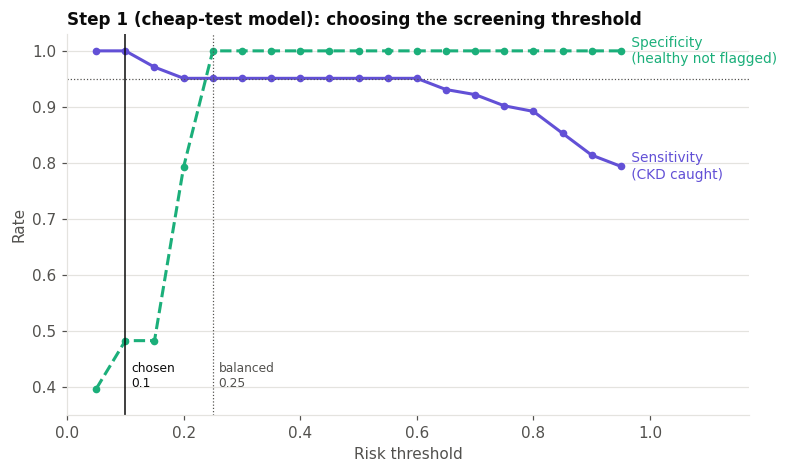

In [ ]:
threshold_chart(cheap_table, SCREEN_T, "Step 1 (cheap-test model): choosing the screening threshold",
                "figures/presc_threshold_step1.png", extra=[(0.25, "balanced\n0.25")])

Sensitivity 1.00 up to 0.10 (specificity 0.483); chosen threshold **0.10**.

## Step 3: Threshold for step 2 (referral, full model)
At step 2 a referral uses a scarce specialist slot, so false alarms matter more. Pasanka's draft required **sensitivity of at least 95%** and took the highest threshold that still met it (0.80). That rule can lower sensitivity without removing any false alarms (at 0.60 and 0.80 specificity is the same, but 0.80 catches fewer CKD patients). The combined rule uses **Youden's index**: the threshold where sensitivity + specificity is highest, with the 95% sensitivity target as a check. Chosen on training patients only.



In [ ]:
full_cv = cv_risk(FEATURES, train)
full_table = threshold_table(full_cv, y_train, np.round(np.arange(0.05, 0.96, 0.05), 2))
full_table["Youden"] = (full_table["Sensitivity"] + full_table["Specificity"] - 1).round(3)
ok = full_table[full_table["Sensitivity"] >= 0.95]
REFER_T = float(ok.loc[ok["Youden"].idxmax(), "Threshold"])
print("Chosen step-2 (referral) threshold:", REFER_T)
full_table

Chosen step-2 (referral) threshold: 0.3


,Threshold,Sensitivity,Specificity,% flagged,Youden
0,0.05,1.000,0.759,72.5,0.759
1,0.10,1.000,0.862,68.8,0.862
2,0.15,1.000,0.948,65.6,0.948
3,0.20,1.000,0.966,65.0,0.966
4,0.25,1.000,0.966,65.0,0.966
5,0.30,1.000,0.983,64.4,0.983
6,0.35,0.990,0.983,63.7,0.973
7,0.40,0.990,0.983,63.7,0.973
8,0.45,0.990,0.983,63.7,0.973
9,0.50,0.980,0.983,63.1,0.963


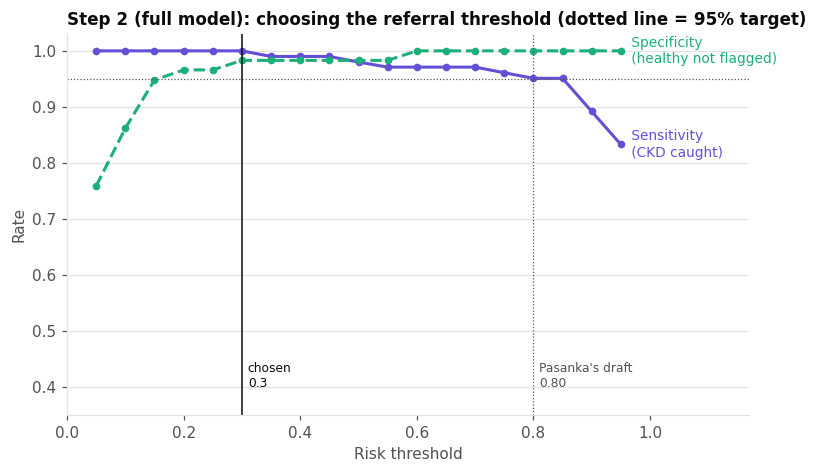

In [ ]:
threshold_chart(full_table, REFER_T, "Step 2 (full model): choosing the referral threshold (dotted line = 95% target)",
                "figures/presc_threshold_step2.png", extra=[(0.80, "Pasanka's draft\n0.80")])

**Check both thresholds once on the 40 test patients.**
Step 1 at 0.10 catches 26 of 26 CKD and flags 7 of 14 healthy people; step 2 at 0.30 catches 26 of 26 with 0 of 14 false alarms (at Pasanka's 0.80: 25 of 26, i.e. one CKD patient missed) false alarms.

In [ ]:
rows = []
for step, model, cols, t in [("Step 1: cheap-test model", cheap_model, CHEAP, SCREEN_T),
                             ("Step 2: full model", full_model, FEATURES, REFER_T),
                             ("Step 2 at Pasanka's 0.80", full_model, FEATURES, 0.80)]:
    se, sp, tp, fn, fp, tn = sens_spec(y_test, (model.predict_proba(test[cols])[:, 1] >= t).astype(int))
    rows.append({"Step": step, "Threshold": t, "CKD caught": f"{tp} of {tp + fn}",
                 "Healthy flagged": f"{fp} of {fp + tn}", "Sensitivity": round(se, 3), "Specificity": round(sp, 3)})
pd.DataFrame(rows).set_index("Step")

,Threshold,CKD caught,Healthy flagged,Sensitivity,Specificity
Step,,,,,
Step 1: cheap-test model,0.1,26 of 26,7 of 14,1.000,0.5
Step 2: full model,0.3,26 of 26,0 of 14,1.000,1.0
Step 2 at Pasanka's 0.80,0.8,25 of 26,0 of 14,0.962,1.0


## Step 4: What this would mean in a real screening programme
In this dataset 64% of patients have CKD, far more than in community screening. The table projects the step-1 cross-validated sensitivity and specificity onto **1,000 people screened, assuming 10% have CKD** (an illustrative figure). Caution: specificity was measured on a healthy control group, so in a real clinic more healthy people would be flagged



In [ ]:
N, PREV = 1000, 0.10
rows = []
for t in [SCREEN_T, 0.25]:
    r = cheap_table.loc[np.isclose(cheap_table["Threshold"], t)].iloc[0]
    ckd, healthy = N * PREV, N * (1 - PREV)
    caught, false_alarms = ckd * r["Sensitivity"], healthy * (1 - r["Specificity"])
    rows.append({"Step-1 threshold": t, "Blood tests needed": round(caught + false_alarms),
                 "Blood tests avoided": round(N - caught - false_alarms),
                 "CKD patients missed at step 1": round(ckd - caught)})
pd.DataFrame(rows).set_index("Step-1 threshold")

,Blood tests needed,Blood tests avoided,CKD patients missed at step 1
Step-1 threshold,,,
0.10,565,435,0
0.25,95,905,5


In [ ]:
At 0.10, 565 blood tests needed and 435 avoided, 0 missed; at 0.25, 95 needed, 905 avoided, 5 missed.

## Step 5: Simple triage rules (shallow decision trees)
Two rule sets, both trained on the 160 training patients and checked once on the 40 test patients:
- **Rule A, at intake (cheap tests only)** from Victor's draft: usable before any blood test.
- **Rule B, after blood tests (all 25 tests)** from Pasanka's draft: a backup to the full model.

In [ ]:
trees, rows = {}, []
for rule, cols in [("A: intake (cheap tests)", CHEAP), ("B: after blood tests", FEATURES)]:
    for depth in (2, 3):
        tree = DecisionTreeClassifier(max_depth=depth, random_state=42).fit(train[cols], y_train)
        trees[(rule, depth)] = (tree, cols)
        row = {"Rule": rule, "Depth": depth}
        for name, data, yy in [("train", train, y_train), ("test", test, y_test)]:
            se, sp, *_ = sens_spec(yy, tree.predict(data[cols]))
            row[f"Sensitivity ({name})"] = round(se, 3)
            row[f"Specificity ({name})"] = round(sp, 3)
        rows.append(row)
pd.DataFrame(rows).set_index(["Rule", "Depth"])

Sensitivity (train)  Specificity (train)  \
Rule                    Depth                                             
A: intake (cheap tests) 2                    0.833                1.000   
                        3                    0.912                1.000   
B: after blood tests    2                    0.990                0.966   
                        3                    0.980                1.000   

                               Sensitivity (test)  Specificity (test)  
Rule                    Depth                                          
A: intake (cheap tests) 2                   0.846                 1.0  
                        3                   1.000                 1.0  
B: after blood tests    2                   0.846                 1.0  
                        3                   0.923                 1.0

In [ ]:
for rule in ["A: intake (cheap tests)", "B: after blood tests"]:
    tree, cols = trees[(rule, 3)]
    print(f"Rule {rule}, depth 3 (codes as in the data):")
    print(export_text(tree, feature_names=cols))

Rule A: intake (cheap tests), depth 3 (codes as in the data):
|--- al <= 0.50
|   |--- htn <= 0.50
|   |   |--- sg <= 2.50
|   |   |   |--- class: 1
|   |   |--- sg >  2.50
|   |   |   |--- class: 0
|   |--- htn >  0.50
|   |   |--- class: 1
|--- al >  0.50
|   |--- class: 1

Rule B: after blood tests, depth 3 (codes as in the data):
|--- hemo <= 5.50
|   |--- pcv <= 6.50
|   |   |--- sod <= 5.50
|   |   |   |--- class: 1
|   |   |--- sod >  5.50
|   |   |   |--- class: 0
|   |--- pcv >  6.50
|   |   |--- class: 0
|--- hemo >  5.50
|   |--- sg <= 2.50
|   |   |--- class: 1
|   |--- sg >  2.50
|   |   |--- su <= 0.50
|   |   |   |--- class: 0
|   |   |--- su >  0.50
|   |   |   |--- class: 1



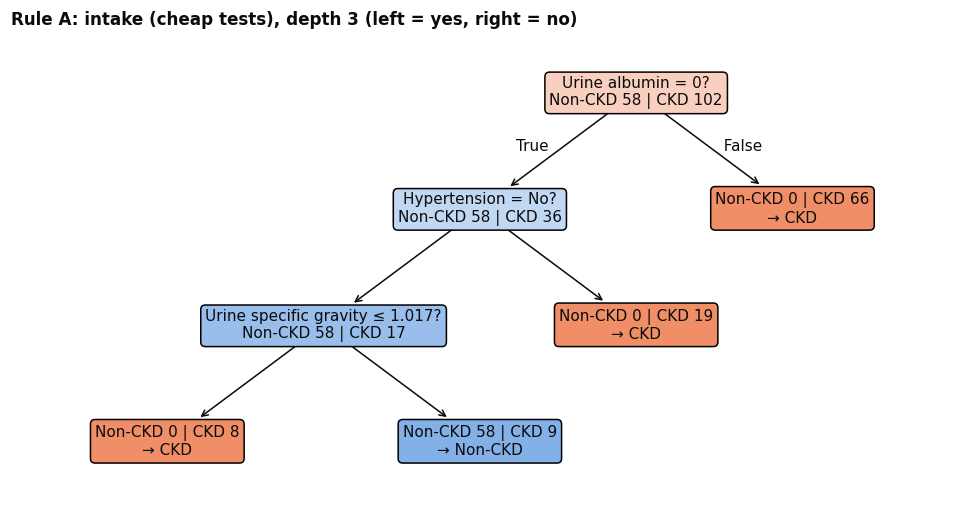

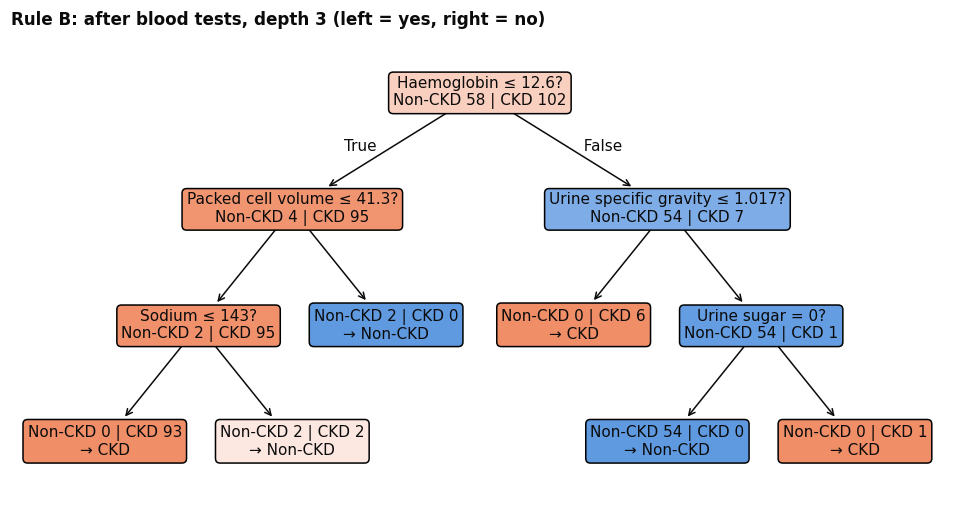

In [ ]:
for rule, file in [("A: intake (cheap tests)", "presc_rule_A_intake.png"),
                   ("B: after blood tests", "presc_rule_B_bloodtests.png")]:
    tree, cols = trees[(rule, 3)]
    fig, ax = plt.subplots(figsize=(11, 5.5))
    plot_readable_tree(ax, tree, cols, raw=raw, names=NAMES, fontsize=10)
    ax.set_title(f"Rule {rule}, depth 3 (left = yes, right = no)")
    fig.savefig(f"figures/{file}")
    plt.show()

Rule A depth 3 sensitivity 0.912 (train) / 1.000 (test); Rule B depth 3 0.980 / 0.923; all specificities 1.0.

## Step 6: Odds ratios for the modifiable factors
An odds ratio (OR) above 1 means higher odds of CKD. Two views:
- **A. Modifiable factors on their own** (Victor): a small model with only BP category, glucose range, hypertension and diabetes. 95% intervals from 500 bootstrap resamples of the training set.
- **B. Adjusted for all other tests** (Pasanka): the same factors inside a model with all 25 tests (fitted without standardising, all 200 patients), so each OR is the effect *on top of* the lab results.

In [ ]:
MOD = ["bp limit", "bgr", "htn", "dm"]
mod_model = LogisticRegression(max_iter=2000).fit(train[MOD], y_train)
rng = np.random.default_rng(42)
boot = np.array([np.exp(LogisticRegression(max_iter=2000).fit(train[MOD].iloc[idx], y_train.iloc[idx]).coef_[0])
                 for idx in (rng.integers(0, len(train), len(train)) for _ in range(500))])
odds_A = pd.DataFrame({
    "Odds ratio": np.exp(mod_model.coef_[0]).round(2),
    "95% CI low": np.percentile(boot, 2.5, axis=0).round(2),
    "95% CI high": np.percentile(boot, 97.5, axis=0).round(2),
}, index=["BP category (per step)", "Random glucose (per range step)", "Hypertension", "Diabetes"])

lr_unscaled = LogisticRegression(max_iter=5000).fit(df[FEATURES], y)
odds_B = pd.Series(np.exp(lr_unscaled.coef_[0]), index=FEATURES)
odds_A["Adjusted OR (all tests)"] = odds_B[MOD].round(2).values
odds_A

,Odds ratio,95% CI low,95% CI high,Adjusted OR (all tests)
BP category (per step),2.64,1.59,4.54,1.79
Random glucose (per range step),2.13,1.42,3.38,1.81
Hypertension,12.47,8.07,19.75,2.03
Diabetes,6.79,4.35,11.14,1.54


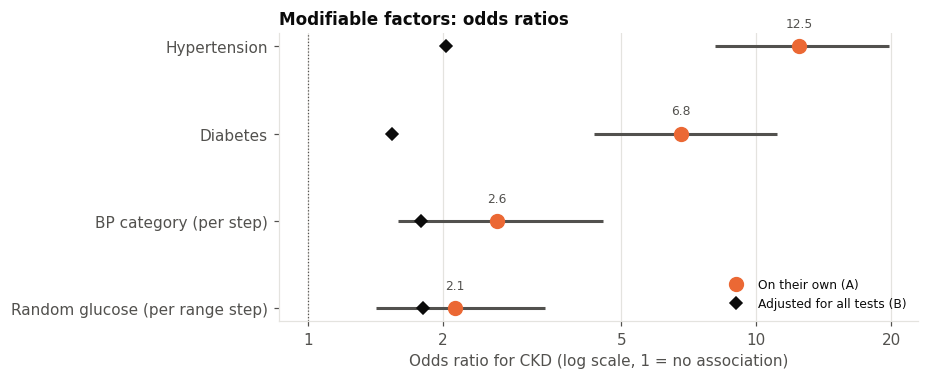

In [ ]:
o = odds_A.sort_values("Odds ratio")
fig, ax = plt.subplots(figsize=(7.5, 3.4))
ax.hlines(range(len(o)), o["95% CI low"], o["95% CI high"], color=MUTED, linewidth=2)
ax.plot(o["Odds ratio"], range(len(o)), "o", color=COLORS["CKD"], markersize=9, label="On their own (A)")
ax.plot(o["Adjusted OR (all tests)"], range(len(o)), "D", color=TEXT, markersize=6, label="Adjusted for all tests (B)")
for i, v in enumerate(o["Odds ratio"]):
    ax.text(v, i + 0.22, f"{v:.1f}", ha="center", fontsize=8, color=MUTED)
ax.axvline(1, color=MUTED, linewidth=0.8, linestyle=":")
ax.set_xscale("log"); ax.set_xticks([1, 2, 5, 10, 20]); ax.set_xticklabels(["1", "2", "5", "10", "20"]); ax.minorticks_off()
ax.set_yticks(range(len(o))); ax.set_yticklabels(o.index)
ax.set_xlabel("Odds ratio for CKD (log scale, 1 = no association)")
ax.set_title("Modifiable factors: odds ratios")
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.legend(loc="lower right", fontsize=8)
fig.savefig("figures/presc_odds_ratios.png")
plt.show()

A: hypertension 12.47, diabetes 6.79, BP category 2.64 per step, glucose 2.13 per step. B: hypertension 2.03, diabetes 1.54.

The adjusted ORs are much smaller because the lab results (haemoglobin, specific gravity, albumin) already carry most of the information. No non-CKD patient has hypertension or diabetes, so all of these ORs are uncertain and show direction and ranking, not exact sizes.

## Step 7: What-if scenarios
**A. Controlling blood pressure and glucose** (Victor): for the test patients with raised BP category or glucose above the lowest range, how does the predicted risk change if BP were controlled (category 0) and/or glucose were in the lowest range, with everything else unchanged?



In [ ]:
who = (test["bp limit"] > 0) | (test["bgr"] > 0)
base = test.loc[who, MOD]
scenarios = {"Current": {}, "BP controlled": {"bp limit": 0}, "Glucose controlled": {"bgr": 0},
             "Both controlled": {"bp limit": 0, "bgr": 0}}
whatif = {}
for name, changes in scenarios.items():
    Xs = base.copy()
    for col, value in changes.items():
        Xs[col] = value
    whatif[name] = mod_model.predict_proba(Xs)[:, 1].mean()
whatif = pd.Series(whatif).round(3)
print(f"Patients in this analysis: {who.sum()}")
whatif

Patients in this analysis: 31


,0
Current,0.660
BP controlled,0.585
Glucose controlled,0.581
Both controlled,0.487


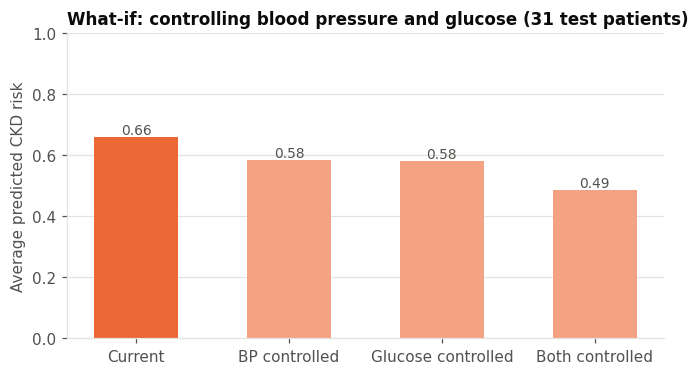

In [ ]:
fig, ax = plt.subplots(figsize=(7, 3.6))
bars = ax.bar(whatif.index, whatif.values, color=[COLORS["CKD"]] + ["#f3a383"] * 3, width=0.55)
for b, v in zip(bars, whatif.values):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.01, f"{v:.2f}", ha="center", fontsize=9, color=MUTED)
ax.set_ylim(0, 1)
ax.set_ylabel("Average predicted CKD risk")
ax.set_title(f"What-if: controlling blood pressure and glucose ({who.sum()} test patients)")
fig.savefig("figures/presc_whatif.png")
plt.show()

Expected (31 patients): average risk 0.660 now; 0.585 with BP controlled; 0.581 with glucose controlled; 0.487 with both.

This only shows how the **model's** risk responds, based on associations; it is not proof that treatment would reduce CKD.

**B. What an odds ratio means for one patient** (Pasanka): take the patient without hypertension whose risk is closest to the referral threshold and switch hypertension from no to yes in the adjusted model. The odds should be multiplied by exactly the adjusted OR for hypertension.

In [ ]:
no_htn = df.index[df["htn"] == 0]
pid = (risk[no_htn] - REFER_T).abs().idxmin()
before = df.loc[[pid], FEATURES]
after = before.copy()
after["htn"] = 1
p0, p1 = lr_unscaled.predict_proba(before)[0, 1], lr_unscaled.predict_proba(after)[0, 1]
odds = lambda p: p / (1 - p)
print(f"Patient {pid}: risk {p0:.3f} -> {p1:.3f}")
print(f"Odds after / odds before = {odds(p1) / odds(p0):.2f}")
print(f"exp(coefficient of htn)  = {odds_B['htn']:.2f}")

Patient 0: risk 0.840 -> 0.914
Odds after / odds before = 2.03
exp(coefficient of htn)  = 2.03


Odds after / odds before = 2.03 = exp(coefficient of hypertension).

## Step 8: Simulate the full two-step pathway on the test set
Step 1: cheap-test model at 0.10. Step 2: flagged patients get blood tests and the full model at 0.30. Confirmed patients are referred.

In [ ]:
p_cheap = cheap_model.predict_proba(test[CHEAP])[:, 1]
p_full = full_model.predict_proba(test[FEATURES])[:, 1]
flagged = p_cheap >= SCREEN_T
referred = flagged & (p_full >= REFER_T)
pathway = pd.Series({
    "Screened (step 1)": len(test),
    "Flagged for blood tests": int(flagged.sum()),
    "Blood tests avoided": int((~flagged).sum()),
    "Referred to nephrology (step 2)": int(referred.sum()),
    "CKD patients referred": int((referred & (y_test == 1)).sum()),
    "CKD patients missed": int(((~referred) & (y_test == 1)).sum()),
    "Healthy people referred": int((referred & (y_test == 0)).sum()),
})
pathway

,0
Screened (step 1),40
Flagged for blood tests,33
Blood tests avoided,7
Referred to nephrology (step 2),26
CKD patients referred,26
CKD patients missed,0
Healthy people referred,0


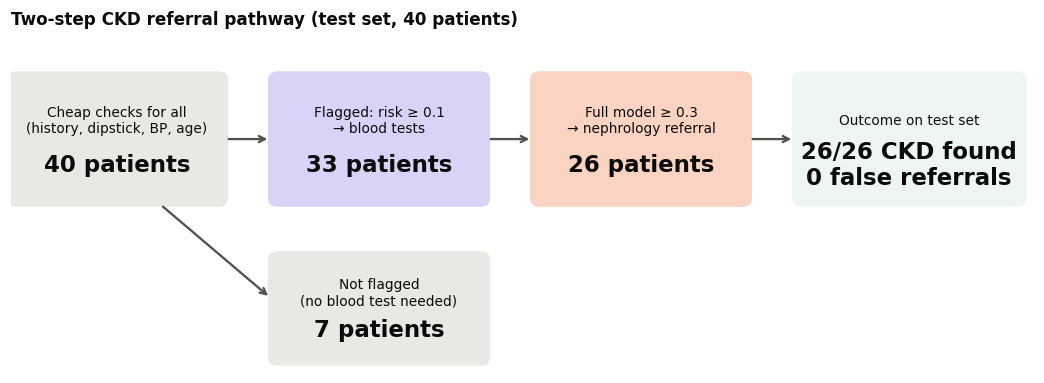

In [ ]:
def box(ax, x, y0, w, h, title, value, color):
    ax.add_patch(FancyBboxPatch((x, y0), w, h, boxstyle="round,pad=0.02,rounding_size=0.04",
                                facecolor=color, edgecolor="none"))
    ax.text(x + w / 2, y0 + h * 0.65, title, ha="center", va="center", fontsize=9, color=TEXT)
    ax.text(x + w / 2, y0 + h * 0.3, value, ha="center", va="center", fontsize=15, fontweight="bold", color=TEXT)

def arrow(ax, x1, y1, x2, y2):
    ax.annotate("", xy=(x2, y2), xytext=(x1, y1), arrowprops=dict(arrowstyle="->", color=MUTED, lw=1.5))

fig, ax = plt.subplots(figsize=(12, 4))
ax.set_xlim(0, 4.1); ax.set_ylim(0, 1.6); ax.axis("off")
box(ax, 0.0, 0.8, 0.85, 0.6, "Cheap checks for all\n(history, dipstick, BP, age)", f"{pathway.iloc[0]} patients", "#e9e8e4")
box(ax, 1.05, 0.8, 0.85, 0.6, f"Flagged: risk ≥ {SCREEN_T}\n→ blood tests", f"{pathway.iloc[1]} patients", "#d9d4f7")
box(ax, 1.05, 0.05, 0.85, 0.5, "Not flagged\n(no blood test needed)", f"{pathway.iloc[2]} patients", "#e9e8e4")
box(ax, 2.1, 0.8, 0.85, 0.6, f"Full model ≥ {REFER_T}\n→ nephrology referral", f"{pathway.iloc[3]} patients", "#fbd3c2")
box(ax, 3.15, 0.8, 0.9, 0.6, "Outcome on test set",
    f"{pathway.iloc[4]}/{pathway.iloc[4] + pathway.iloc[5]} CKD found\n{pathway.iloc[6]} false referrals", "#eef6f1")
arrow(ax, 0.86, 1.1, 1.04, 1.1); arrow(ax, 0.6, 0.79, 1.04, 0.35)
arrow(ax, 1.91, 1.1, 2.09, 1.1); arrow(ax, 2.96, 1.1, 3.14, 1.1)
ax.set_title("Two-step CKD referral pathway (test set, 40 patients)", loc="left")
fig.savefig("figures/presc_pathway.png")
plt.show()

40 screened → 33 flagged for blood tests (7 avoided) → 26 referred; 26 of 26 CKD patients referred, 0 healthy people referred.

## Step 9: OR-Tools (course Lab 3)
### 9A. Who gets the N referral slots? (Pasanka)
One yes/no variable per patient. The model maximises the total risk of the referred patients, subject to: at most N patients referred, and only patients with risk ≥ the referral threshold are eligible. Many CKD patients have a risk of about 1.0, so the top N is partly a tie; ties are broken towards the more advanced stage.

A variant adds a rule the care team can change: **at least half of the slots go to early-stage patients (stage 2–3)**, where referral can still slow progression. The 50% share is an assumption (`EARLY_SHARE`; set it to 0 to switch the rule off). Stage is not a model input; it is only used here as a rule, because it is known once blood tests (creatinine) are available at step 2.

In [ ]:
stage = df["stage"].str.extract(r"(\d)")[0].astype(int)
early = stage.isin([2, 3])
EARLY_SHARE = 0.5
eligible = risk >= REFER_T
print("Eligible for referral (risk >= threshold):", int(eligible.sum()))

def choose_patients(n_slots, min_early=0):
    model = cp_model.CpModel()
    pick = {i: model.NewBoolVar(f"pick_{i}") for i in df.index}
    for i in df.index:
        if not eligible[i]:
            model.Add(pick[i] == 0)                       # below the threshold: not eligible
    model.Add(sum(pick.values()) <= n_slots)              # limited slots
    if min_early:
        model.Add(sum(pick[i] for i in df.index if early[i]) >= min_early)
    # maximise total risk (in 1/10000 units), small bonus for later stage to break ties
    model.Maximize(sum((int(round(risk[i] * 10000)) * 10 + int(stage[i])) * pick[i] for i in df.index))
    solver = cp_model.CpSolver()
    status = solver.Solve(model)
    assert status in (cp_model.OPTIMAL, cp_model.FEASIBLE)
    return [i for i in df.index if solver.Value(pick[i])]

selected, rows = {}, []
for n_slots in (5, 10, 15):
    for rule, min_early in (("Highest risk only", 0),
                            ("At least 50% early stage", int(np.ceil(n_slots * EARLY_SHARE)))):
        ids = choose_patients(n_slots, min_early)
        selected[(n_slots, rule)] = ids
        rows.append({"Slots": n_slots, "Rule": rule, "Total risk": round(risk[ids].sum(), 2),
                     "Mean risk": round(risk[ids].mean(), 3), "Early-stage patients": int(early[ids].sum()),
                     "True CKD": int(y[ids].sum())})
slots_table = pd.DataFrame(rows).set_index(["Slots", "Rule"])
slots_table

Eligible for referral (risk >= threshold): 129


Total risk  Mean risk  Early-stage patients  \
Slots Rule                                                                    
5     Highest risk only                5.0        1.0                     0   
      At least 50% early stage         5.0        1.0                     3   
10    Highest risk only               10.0        1.0                     0   
      At least 50% early stage        10.0        1.0                     5   
15    Highest risk only               15.0        1.0                     0   
      At least 50% early stage        15.0        1.0                     8   

                                True CKD  
Slots Rule                                
5     Highest risk only                5  
      At least 50% early stage         5  
10    Highest risk only               10  
      At least 50% early stage        10  
15    Highest risk only               15  
      At least 50% early stage        15

In [ ]:
for (n_slots, rule), ids in selected.items():
    print(f"{n_slots} slots, {rule}:")
    print(scores.loc[ids].sort_values(["risk", "stage"], ascending=False).to_string())
    print()

5 slots, Highest risk only:
     risk stage  class
163   1.0    s5      1
175   1.0    s5      1
178   1.0    s5      1
192   1.0    s5      1
194   1.0    s5      1

5 slots, At least 50% early stage:
     risk stage  class
175   1.0    s5      1
178   1.0    s5      1
9     1.0    s3      1
41    1.0    s3      1
83    1.0    s3      1

10 slots, Highest risk only:
     risk stage  class
111   1.0    s5      1
113   1.0    s5      1
140   1.0    s5      1
141   1.0    s5      1
146   1.0    s5      1
163   1.0    s5      1
175   1.0    s5      1
178   1.0    s5      1
192   1.0    s5      1
194   1.0    s5      1

10 slots, At least 50% early stage:
     risk stage  class
113   1.0    s5      1
140   1.0    s5      1
141   1.0    s5      1
146   1.0    s5      1
163   1.0    s5      1
9     1.0    s3      1
41    1.0    s3      1
83    1.0    s3      1
112   1.0    s3      1
161   1.0    s3      1

15 slots, Highest risk only:
     risk stage  class
87    1.0    s5      1
92    1.0  

129 eligible patients; for 5, 10 and 15 slots every selected patient is true CKD and the total risk is 5.0, 10.0 and 15.0 with or without the early-stage rule, which gives 3, 5 and 8 early-stage patients.

### 9B. Booking the limited blood-test slots (Victor)
Before referral, the flagged patients from step 1 need blood tests, and the lab cannot test everyone at once. Suppose the flagged test patients must be booked into **3 days with 10 slots per day**, and some cannot come on day 1 (illustrative: about a quarter, random with a fixed seed). The solver maximises priority: higher cheap-test risk counts more, and earlier days count more (day 1 × 3, day 2 × 2, day 3 × 1). Patients with risk 0.9 or higher must get a slot.

In [ ]:
queue = test.loc[flagged].copy()
queue["risk"] = p_cheap[flagged].round(3)
queue["ckd_actual"] = y_test[flagged]
rng = np.random.default_rng(7)
queue["unavailable_day1"] = rng.random(len(queue)) < 0.25

DAYS, SLOTS_PER_DAY, DAY_WEIGHT = [1, 2, 3], 10, {1: 3, 2: 2, 3: 1}
score = {i: int(round(100 * r)) for i, r in queue["risk"].items()}

model = cp_model.CpModel()
xv = {(i, day): model.NewBoolVar(f"x_{i}_{day}") for i in queue.index for day in DAYS}
for i in queue.index:
    model.Add(sum(xv[i, day] for day in DAYS) <= 1)              # at most one slot per patient
    if queue.loc[i, "unavailable_day1"]:
        model.Add(xv[i, 1] == 0)                                 # cannot come on day 1
    if queue.loc[i, "risk"] >= 0.9:
        model.Add(sum(xv[i, day] for day in DAYS) == 1)          # high risk must be booked
for day in DAYS:
    model.Add(sum(xv[i, day] for i in queue.index) <= SLOTS_PER_DAY)  # daily capacity
model.Maximize(sum(score[i] * DAY_WEIGHT[day] * xv[i, day] for i in queue.index for day in DAYS))

solver = cp_model.CpSolver()
status = solver.Solve(model)
print("Solver status:", solver.StatusName(status))

queue["day"] = 0
for (i, day), var in xv.items():
    if solver.Value(var):
        queue.loc[i, "day"] = day
schedule = queue.groupby("day").agg(patients=("risk", "size"), mean_risk=("risk", "mean"),
                                    min_risk=("risk", "min"), actual_ckd=("ckd_actual", "sum")).round(2)
schedule.index = schedule.index.map(lambda dd: "Waiting (next round)" if dd == 0 else f"Day {dd}")
schedule

Solver status: OPTIMAL


,patients,mean_risk,min_risk,actual_ckd
day,,,,
Waiting (next round),3,0.17,0.16,0
Day 1,10,1.00,1.00,10
Day 2,10,1.00,0.99,10
Day 3,10,0.58,0.19,6


status OPTIMAL; 30 booked and 3 waiting, all waiting patients with risk below 0.2; days 1 and 2 filled with patients at risk 0.99 or higher; all 26 CKD patients get a slot.

## Step 10: Recommendations for the care coordinator
1. **Use a two-step pathway.** Step 1: cheap checks for everyone (history, urine dipstick, BP category, age); send for blood tests if the cheap-test risk is 0.10 or higher. Step 2: refer to nephrology if the full-model risk is 0.30 or higher. On the 40 test patients this found all 26 CKD patients with no false referrals and avoided 7 blood tests; in a population where about 10% have CKD it would avoid roughly 435 of every 1,000 blood tests.
2. **Use different thresholds for the two steps.** Step 1 must miss nobody (a false alarm only costs one blood test), so it uses a low threshold (0.10). Step 2 uses a scarce specialist slot, so it uses the threshold with the best balance of sensitivity and specificity (Youden's index): 0.30, with sensitivity 1.000 and specificity 0.983 in cross-validation. The earlier rule (highest threshold with at least 95% sensitivity, 0.80) would have missed one of the 26 test CKD patients without removing any false alarm.
3. **Keep two backup rules for when the score cannot be calculated.** At intake (Rule A): send for blood tests if urine albumin is 1+ or more, OR the patient has hypertension, OR urine specific gravity is 1.017 or lower (sensitivity 0.91 train / 1.00 test, no false alarms). After blood tests (Rule B): haemoglobin 12.6 g/dL or lower, followed by packed cell volume and sodium, otherwise specific gravity and urine sugar (0.98 / 0.92).
4. **Allocate scarce referral slots with OR-Tools.** With 5, 10 or 15 slots, only patients at or above the referral threshold are eligible (129 of 200), highest risk first; every selected patient was true CKD. Because many patients share a risk of about 1.0, the team can reserve at least half of the slots for early-stage patients (stage 2–3), where referral can still slow progression, at no loss in total risk (3, 5 and 8 early-stage patients). The 50% share is an assumption to confirm with the care team.
5. **When lab capacity is short, book blood tests by risk.** The scheduling model fills the earliest days with the highest-risk patients and guarantees a slot for everyone with risk 0.9 or higher.
6. **Prioritise blood pressure and glucose control.** Hypertension (OR 12.5 on its own, 2.0 after adjusting for all lab results) and diabetes (6.8 and 1.5) are the strongest modifiable associations, and each step up in BP category or glucose range roughly doubles the odds. In the what-if analysis, controlling both BP and glucose lowered the model's average risk from 0.66 to 0.49.
7. **Before use:** these are associations from one visit per patient at one hospital (200 patients), the score shows current CKD rather than future progression, and the non-CKD group has no comorbidities, so the thresholds must be re-checked on a typical clinic population with the hospital's own lab ranges. The tool supports, and does not replace, clinical judgement.

## Step 11: Download all figures

In [ ]:
import shutil
from google.colab import files

cheap_table.to_csv("figures/presc_thresholds_step1.csv", index=False)
full_table.to_csv("figures/presc_thresholds_step2.csv", index=False)
odds_A.to_csv("figures/presc_odds_ratios.csv")
slots_table.to_csv("figures/presc_slots.csv")
schedule.to_csv("figures/presc_schedule.csv")
shutil.make_archive("prescriptive_figures", "zip", "figures")
files.download("prescriptive_figures.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>